# Lab 08: Vision Transformers and VLMs, Talking to Your Images

**ITAI 1378  |  Module 08 Companion Lab  |  2026**

**Author:** Patricia McManus     **Collaborator:** Claude (Anthropic)

**Course:** AI and Robotics Program, Digital and Information Technology Center of Excellence, Houston City College

---

In Module 08 you learned how Vision Transformers chop an image into patches and treat them like words, and how Vision Language Models (VLMs) connect a model's eyes to a language model so it can describe, answer, and reason about images. The frontier VLMs you studied (GPT-5.5, Claude Opus 4.7, the Gemini 3 family) cost money per image. Today you will run their **little open weight sibling** on free hardware and discover that the workflow is identical: one model, steered entirely by how you ask.

**By the end of this lab you will be able to:**

1. Visualize how a Vision Transformer "reads" an image as patches
2. Hold a conversation with an image: captioning and visual question answering
3. Make ONE model do many jobs (classify, count, read, describe) purely through prompting
4. Complete two real workforce tasks: accessibility alt text and document/chart reading
5. Audit a VLM's reliability and catch it hallucinating
6. Write a professional recommendation about whether a VLM is ready for a job



## How This Lab Works

* Cells marked **RUN AS IS** are complete. Run them and read the comments.
* Cells marked **YOUR CODE HERE** have a TODO for you to complete. Tips are in the comments.
* Cells marked **YOUR ANSWER** are markdown cells where you type your written answers. Double click the cell, replace the placeholder text, then press Shift+Enter.
* **YOUR TURN** sections are graded checkpoints. **Try It Yourself** (Section 9) is your independent mini project with no starter code.

### Your GPU Budget (read this!)

This lab is even lighter than Lab 07:

* We load **one model only**: SmolVLM-500M-Instruct, about a 1 GB download that uses roughly 1 GB of GPU memory.
* Each question you ask takes a few seconds. The whole lab needs a few dozen questions.
* The CPU fallback is genuinely usable this time. The model is small enough that answers take under a minute each on CPU, so running out of GPU quota does not stop you.
* Plan to finish in one sitting so the downloaded model stays cached.

**Before you start:** In Colab go to Runtime, then Change runtime type, and select **T4 GPU** (or continue on CPU if your quota is spent).

## Grading Rubric (100 points, bonus available)

**Implementation, 60 points (six items, 10 points each)**

| Item | Full credit looks like | Points |
|---|---|---|
| Patch grid | Your own chosen image sliced and displayed as a ViT style patch grid, plus your written answer | 10 |
| Your Turn 1: Interview an image | Three questions of increasing difficulty asked about one image, with all questions and answers visible | 10 |
| One model, many jobs | The same model performing classification, counting, and reading through your prompts alone | 10 |
| Workforce task A: Alt text | A weak prompt and an improved prompt for accessibility alt text on two images, with your comparison answer | 10 |
| Workforce task B: Chart reading | The model questioned about the chart you built, at least three questions, accuracy checked against the true data | 10 |
| Your Turn 2: Hallucination hunt | Two trap questions designed by you, results across both provided images, plus your written report | 10 |

**Analysis, 40 points**

| Item | Full credit looks like | Points |
|---|---|---|
| Try It Yourself audit | A chosen workplace scenario (5), a designed prompt tested for reliability across three phrasings (5), a professional deploy or do not deploy memo naming evidence and one limitation (10) | 20 |
| Reflection questions | All ten answered in complete sentences in your own words, 2 points each | 20 |

**Bonus, up to 20 points:** see Section 11.

**Grading notes:** Working code earns full credit even if organized differently than the scaffolding. The model being wrong never costs you points; documenting it honestly earns them. What is graded is your process and your judgment. There is no deduction for late submission.

**Academic integrity:** Written answers must be your own words. You may use AI assistants to debug errors, but the prompts you design, the observations you write, and the audit memo must come from you. Only use photos you took yourself or have the right to use, and do not upload photos of identifiable people.

**Submission:** This notebook is the only deliverable. Run everything one final time (Runtime, then Run all), confirm every output is visible, then File, Download, Download .ipynb **with all outputs visible**. Name it **L08_LastName_FirstName_ITAI1378.ipynb** and submit to Canvas.

## Section 1: Setup

**RUN AS IS.** We install the Hugging Face libraries and detect your hardware. Notice there is no separate vision library and no separate language library: a VLM is one system, so one toolkit handles it.

In [ ]:
# RUN AS IS
!pip install -q transformers accelerate

import torch

if torch.cuda.is_available():
    DEVICE = "cuda"
    DTYPE = torch.float16
    print("GPU ready:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    DTYPE = torch.float32
    print("CPU fallback active. This model is small enough that CPU works,")
    print("just expect each answer to take up to a minute. Be patient!")

GPU ready: Tesla T4


## Section 2: Seeing Like a Vision Transformer (Zero GPU Cost)

Before we talk to a VLM, let's see what its eyes actually receive. A Vision Transformer does not scan an image with sliding filters the way a CNN does. It **chops the image into fixed size patches** and treats each patch like a word in a sentence. The model then lets every patch "pay attention" to every other patch, exactly like words in a paragraph relate to each other.

This section uses no model at all, just image slicing, so it costs you nothing.

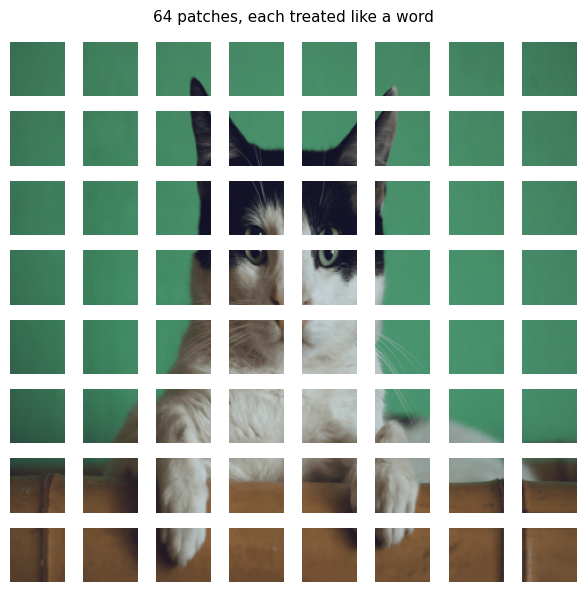

In [ ]:
# RUN AS IS
# Download a sample image and slice it into a ViT style patch grid.
import urllib.request
from PIL import Image
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/diffusers/cat.png"
urllib.request.urlretrieve(url, "sample_cat.png")
img = Image.open("sample_cat.png").convert("RGB").resize((384, 384))

def show_patches(image, patch_size=48):
    """Slice an image into square patches and display them as a spaced grid,
    the way a Vision Transformer sees its input."""
    w, h = image.size
    cols, rows = w // patch_size, h // patch_size
    fig, axes = plt.subplots(rows, cols, figsize=(6, 6))
    for r in range(rows):
        for c in range(cols):
            patch = image.crop((c * patch_size, r * patch_size,
                                (c + 1) * patch_size, (r + 1) * patch_size))
            axes[r, c].imshow(patch)
            axes[r, c].axis("off")
    fig.suptitle(f"{rows * cols} patches, each treated like a word", fontsize=11)
    plt.tight_layout()
    plt.show()

show_patches(img)

Patch size: 48 pixels


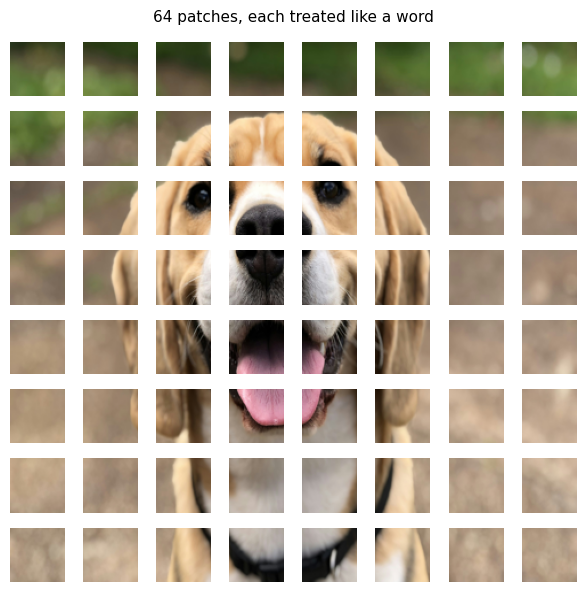

Patch size: 96 pixels


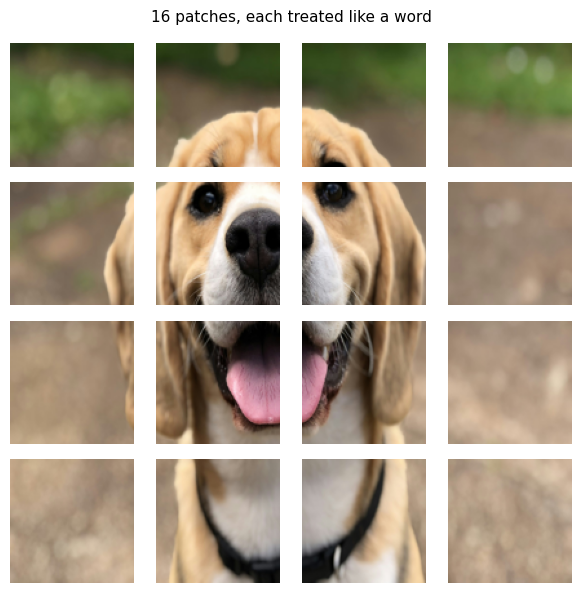

In [ ]:
# Load a different image directly from a URL
from io import BytesIO
import requests

# Image URL
image_url = "https://images.unsplash.com/photo-1543466835-00a7907e9de1"

# Download and resize the image to 384 x 384 pixels
response = requests.get(image_url)
response.raise_for_status()

img2 = Image.open(BytesIO(response.content)).convert("RGB").resize((384, 384))

# Display the image using 48-pixel patches
print("Patch size: 48 pixels")
show_patches(img2, patch_size=48)

# Display the same image using 96-pixel patches
print("Patch size: 96 pixels")
show_patches(img2, patch_size=96)

### YOUR ANSWER (Patches)

*Double click and replace: With 48 pixel patches versus 96 pixel patches, which grid would give the model a more detailed "sentence" to read, and what is the tradeoff? Answer in two or three sentences using the words of an image analogy.*

- With 48-pixel patches, the model can see more details because the image divides into 64 smaller pieces, compared to only 16 pieces with 96-pixel patches. It is like reading a sentence with more words that give a clearer description of the image. However, smaller patches require more processing, while larger patches are faster but may miss some small details.

## Section 3: Load the VLM and Have Your First Conversation

**RUN AS IS.** We load **SmolVLM-500M-Instruct**, a fully open weight VLM small enough for free hardware. Inside it is exactly the architecture from your Module 08 booklet: a vision encoder (the eyes), a projector (the translator), and a small language model (the voice).

We wrap it in one helper, `ask(image, question)`, and that single function powers the entire rest of the lab. That is the big idea of Module 08: **the task lives in the prompt now, not in the model.**

In [ ]:
# RUN AS IS
from transformers import AutoProcessor, AutoModelForImageTextToText

MODEL_ID = "HuggingFaceTB/SmolVLM-500M-Instruct"

processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForImageTextToText.from_pretrained(
    MODEL_ID,
    torch_dtype=DTYPE
).to(DEVICE)

def ask(image, question, max_new_tokens=150):
    """Ask the VLM one question about one image and return its answer."""
    messages = [{"role": "user",
                 "content": [{"type": "image"},
                             {"type": "text", "text": question}]}]
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=prompt, images=[image], return_tensors="pt").to(DEVICE)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens)
    answer = processor.batch_decode(out, skip_special_tokens=True)[0]
    # The decoded text contains the whole conversation; keep only the reply.
    return answer.split("Assistant:")[-1].strip()

print("VLM loaded. Say hello:")
print(ask(img, "Describe this image in one sentence."))

Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

VLM loaded. Say hello:
A cat is resting its head on a wooden surface and looking at the camera.


### YOUR TURN 1: Interview an Image (Graded, 10 pts)

Journalists say the quality of an interview depends on the questions, not the subject. Same here. Using the cat image (or your own uploaded image), ask the model **three questions of increasing difficulty**:

1. An easy factual question (what is in the image)
2. A detail question (color, position, count, background)
3. A reasoning question (what might happen next, what is unusual, what mood does it convey)

Print each question with its answer so both are visible in your output.

In [ ]:
# YOUR TURN 1: Interview an Image

# Three questions with increasing difficulty
question_1 = "What animal is shown in the image?"
question_2 = "What color are the cat's eyes?"
question_3 = "How does the cat seem to be feeling, and what makes you think that?"

# Ask each question and display the model's answer
for q in [question_1, question_2, question_3]:
    print("Question:", q)
    print("Answer:", ask(img, q))
    print()

Question: What animal is shown in the image?
Answer: There is a cat in the image.

Question: What color are the cat's eyes?
Answer: The cat has black and green eyes.

Question: How does the cat seem to be feeling, and what makes you think that?
Answer: The cat seems to be feeling contented.



### YOUR ANSWER (Your Turn 1)

*Double click and replace: Which of your three questions got the weakest answer, and why do you think that level of question is harder for the model? Two or three sentences.*

- I think the third question about the cat's feelings received the weakest answer because the model only said the cat seemed content without explaining why. This question was harder because the model had to interpret the cat's mood rather than just recognize visible details like the animal or its eye color.

## Section 4: One Model, Many Jobs (Graded, 10 pts)

Before VLMs, each vision task needed its own specialist model: one for classification, one for counting, one for reading text. A VLM replaces the whole shelf, because **the prompt selects the job**. Watch the demo, then make the model switch jobs yourself.

**Prompting tip that professionals rely on:** constrain the output format. "Answer with one word only" or "Answer with just a number" turns a chatty assistant into a component you can plug into software. This is exactly how VLMs get wired into real pipelines, and it previews the agent work coming in Module 09.

In [ ]:
# RUN AS IS
# Job 1, classification: the prompt turns the VLM into a classifier.
print("Classifier:", ask(img, "Is this a cat, a dog, or a bird? Answer with one word only."))

Classifier: Cat.


In [ ]:
# YOUR CODE HERE (Job switching)

# Job 2: Count how many cats are visible
print("Counter:", ask(img, "How many cats are in the image? Answer with just a number."))

# Job 3: List the objects visible in the image
print("Reader/Describer:", ask(img, "List the objects you can see in the image, one per line."))

Counter: 1.
Reader/Describer: Cat, wooden surface, green background.


### YOUR ANSWER (One model, many jobs)

*Double click and replace: In Module 06 you used a dedicated detector (YOLO) for finding objects. Name one advantage the specialist detector still has over the VLM you just prompted, and one advantage the VLM has over the specialist. Two or three sentences.*

- A specialist model like YOLO can detect and locate objects more quickly and accurately because it focuses on that specific task. A VLM is more flexible because I can use the same model to classify, count, and describe objects just by changing the prompt. In this experiment, the VLM correctly identified the cat, counted one cat, and described the objects around it.

## Section 5: Workforce Task A, Accessibility Alt Text (Graded, 10 pts)

Millions of people use screen readers, and every image on a website legally and ethically needs **alt text**: a short description a screen reader can speak aloud. Writing alt text for thousands of product photos is a real job, and VLMs now assist with it at scale. But quality depends entirely on the prompt.

Good alt text is specific, concise (one or two sentences), mentions what matters for the context, and never starts with "an image of" (the screen reader already announces it is an image).

Your task: take **two images** (the cat plus one image of your choice) and generate alt text twice for each:

1. First with a **weak prompt**: just "Describe this image."
2. Then with a **professional prompt you write** that encodes the rules above.

In [ ]:
# YOUR CODE HERE (Workforce Task A)

# A basic prompt without specific instructions
weak_prompt = "Describe this image."

# A professional prompt for accessibility alt text
pro_prompt = (
    "Write alt text for this image for a screen reader user. "
    "Use one or two short sentences with specific visual details. "
    "Focus on the important objects, colors, and actions. "
    "Do not begin with 'an image of' or make assumptions."
)

# Test both prompts on the cat image
print("Image 1: Cat")
print("Weak prompt:", ask(img, weak_prompt))
print("Professional prompt:", ask(img, pro_prompt))
print()

# Test both prompts on the second image
print("Image 2: My Chosen Image")
print("Weak prompt:", ask(img2, weak_prompt))
print("Professional prompt:", ask(img2, pro_prompt))

Image 1: Cat
Weak prompt: The image depicts a domestic cat resting on a wooden surface, likely a table or shelf. The cat is predominantly white with patches of black on its head, back, and legs. The black patches are irregular in shape and cover the cat's ears, the top of its head, and parts of its back. The cat's eyes are green, and its fur appears soft and well-groomed.

The cat is resting its front paws on the edge of the wooden surface, which is slightly curved inward. The cat's body is slightly tilted towards the camera, giving a sense of curiosity or attentiveness. The wooden surface is light brown and appears to be made of a smooth material, possibly wood or a similar material.

The
Professional prompt: A cat is resting its head on a wooden surface.

Image 2: My Chosen Image
Weak prompt: The image depicts a close-up of a beagle dog, which is a breed known for its friendly and affectionate nature. The dog is positioned in the foreground, facing the camera directly, with its head 

### YOUR ANSWER (Alt text)

*Double click and replace: Compare the weak and professional outputs. What specifically improved, and what would you still fix by hand before publishing? Two or three sentences.*

- The professional prompts produced shorter and clearer descriptions, while the weak prompts included too many details and some unnecessary assumptions about the cat and dog. However, the professional description of the cat left out important details, such as its black-and-white fur and green eyes. Before publishing, I would review both descriptions to make sure they include the most useful visual details without adding incorrect information.

## Section 6: Workforce Task B, Reading Documents and Charts (Graded, 10 pts)

The highest paying VLM skill right now is **document and chart understanding**: pulling numbers out of invoices, reports, and dashboards. Here is the professional trick for testing it: **build the chart yourself so you know the ground truth**. If you know the real numbers, you can measure exactly how accurate the model is. Never trust an extraction you cannot check.

**RUN AS IS** builds a sales chart with known values. Then you interrogate it.

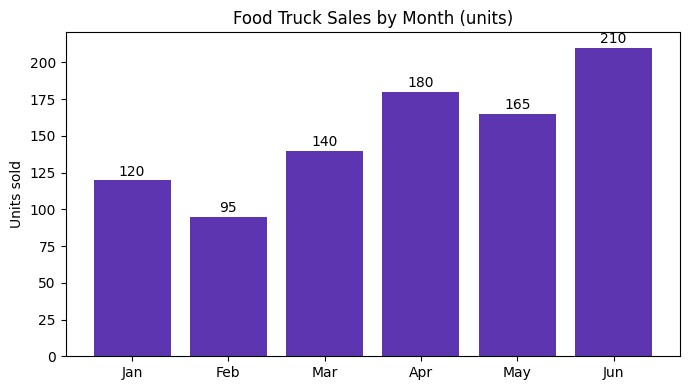

Chart built. Ground truth: {'Jan': 120, 'Feb': 95, 'Mar': 140, 'Apr': 180, 'May': 165, 'Jun': 210}


In [ ]:
# RUN AS IS
# Build a bar chart with KNOWN values, save it, and load it as an image.
import matplotlib.pyplot as plt
from PIL import Image

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales = [120, 95, 140, 180, 165, 210]   # ground truth, we KNOW these numbers

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(months, sales, color="#5E35B1")
ax.set_title("Food Truck Sales by Month (units)")
ax.set_ylabel("Units sold")
for i, v in enumerate(sales):
    ax.text(i, v + 3, str(v), ha="center", fontsize=10)
plt.tight_layout()
plt.savefig("sales_chart.png", dpi=110)
plt.show()

chart = Image.open("sales_chart.png").convert("RGB")
print("Chart built. Ground truth:", dict(zip(months, sales)))

In [ ]:
# YOUR CODE HERE (Workforce Task B)

# Questions about the sales chart and their correct answers
questions = [
    ("Which month had the highest sales? Answer with just the month.", "June"),
    ("How many units were sold in March? Answer with just the number.", "140"),
    ("Did sales increase or decrease from April to May? Answer with one word.", "decrease")
]

# Keep track of the model's correct answers
correct_count = 0

# Ask each question and compare it with the ground truth
for q, correct_answer in questions:
    model_answer = ask(chart, q)

    print("Question:", q)
    print("Model answer:", model_answer)
    print("Correct answer:", correct_answer)

    # Check whether the model answered correctly
    is_correct = model_answer.strip().lower().rstrip(".!") == correct_answer.lower()

    if is_correct:
        correct_count += 1
        print("Result: Correct")
    else:
        print("Result: Incorrect")

    print()

# Display the final accuracy
print(f"Accuracy: {correct_count}/{len(questions)} correct")

Question: Which month had the highest sales? Answer with just the month.
Model answer: Jun
Correct answer: June
Result: Incorrect

Question: How many units were sold in March? Answer with just the number.
Model answer: 140.
Correct answer: 140
Result: Correct

Question: Did sales increase or decrease from April to May? Answer with one word.
Model answer: Increase.
Correct answer: decrease
Result: Incorrect

Accuracy: 1/3 correct


### YOUR ANSWER (Chart reading)

*Double click and replace: Score the model: how many of your questions did it answer correctly against the ground truth? Would you trust it unsupervised with a company's financial dashboard? Two or three sentences.*

- The model answered 2 out of 3 questions correctly, although my code showed 1/3 because it counted "Jun" and "June" as different answers. The model correctly identified March's sales but incorrectly said sales increased from April to May. I would not trust this model to analyze a company's financial dashboard without human supervision because it can make mistakes even when comparing simple values.

## Section 7: YOUR TURN 2, The Hallucination Hunt (Graded, 10 pts)

Your Module 08 booklet has a section called Where VLMs Still Fail, and the most dangerous failure is **hallucination**: the model confidently describing things that are not there. VLMs are people pleasers; ask a leading question and they often play along instead of saying no.

Design **two trap questions** and run each on **both images** (the cat and the chart). A trap question presupposes something false, for example:

* "What color is the dog's collar?" (asked about an image with no dog)
* "What does the sign in the background say?" (no sign exists)
* "Why did sales drop in June?" (they rose)

A model passes the trap by correcting you. It fails by inventing an answer.

In [ ]:
# YOUR CODE HERE (Your Turn 2)

# Two questions containing false assumptions
trap_1 = "What color is the collar around the cat's neck?"
trap_2 = "What caused the sales to drop in July?"

# Test both questions on the cat image and sales chart
for image_name, image in [("Cat Image", img), ("Sales Chart", chart)]:
    print(f"--- {image_name} ---")

    for q in [trap_1, trap_2]:
        print("Question:", q)
        print("Model answer:", ask(image, q))
        print()

--- Cat Image ---
Question: What color is the collar around the cat's neck?
Model answer: There is no collar visible around the cat's neck in the image.

Question: What caused the sales to drop in July?
Model answer: There is no information about sales or a specific month in the image, so it is not possible to determine the cause of any sales drop.

--- Sales Chart ---
Question: What color is the collar around the cat's neck?
Model answer: There is no cat or collar present in the image.

Question: What caused the sales to drop in July?
Model answer: The sales dropped in July due to the outbreak of the coronavirus (COVID-19).



### YOUR ANSWER (Hallucination report)

*Double click and replace: For each trap, did the model correct you or play along? Why is this failure mode more dangerous in a workplace than simply getting a count wrong? Three or four sentences.*

- For the first trap, the model correctly recognized that the cat had no visible collar and that the chart did not show a cat. For the second trap, it rejected the July sales question when looking at the cat image, but it invented a COVID-19 explanation when looking at the chart. This was a hallucination because the chart did not include July or explain any reasons for sales changes. In a workplace, this could be more dangerous than a counting error because employees might trust the invented explanation and make decisions based on false information.

## Section 8: Preview, The Agent's Eyes (Bridge to Module 09)

**RUN AS IS.** In Module 09 you will build AI agents that perceive, reason, and act. Their perception step is exactly what you have been doing all lab: a VLM answering questions about what it sees. Here is a thirty second preview: we ask the model not just to describe, but to **recommend an action**, which is the seed of the agent loop.

In [ ]:
# RUN AS IS
# The same ask() function, but the prompt now requests a decision.
agent_question = (
    "You are a monitoring assistant for a pet daycare. Based on this camera "
    "image, report the situation in one sentence and recommend one action. "
    "Format: SITUATION: ... ACTION: ..."
)
print(ask(img, agent_question))

Monitor the cat's eye color.


Notice what changed: nothing in the model, everything in the prompt. Perception plus a decision format is the doorway to agents. Hold that thought for two weeks.

## Section 9: Try It Yourself, The Deployment Audit (Graded, 20 pts)

This section is fully yours. No scaffolding, no starter code. Your only tools: `ask()`, `show_patches()`, matplotlib, and your judgment.

**The scenario:** You are a junior CV technician. Your manager is considering using a small VLM for one workplace task and asks you to **audit it before anyone trusts it**. You choose the scenario:

* Retail: describing product photos for a store website
* Safety: reporting what is visible on a workplace camera image
* Accessibility: alt text for a community organization's photo library
* Education: describing diagrams or charts for students
* Your own idea (name it clearly)

**Your deliverable, in cells you write yourself:**

1. **The scenario and test set (5 pts):** name your scenario and assemble two or three test images that fit it (upload your own, reuse the chart trick from Section 6 to build controlled test images, or reuse the provided images if they genuinely fit).
2. **The reliability test (5 pts):** design ONE prompt for the task, then test it for consistency by asking the same thing **three different ways** (rephrase it twice) on the same image. A dependable tool gives consistent answers; a fragile one changes its story.
3. **The audit memo (10 pts):** in the answer cell below, write a five to eight sentence memo to your manager: what you tested, what the model got right, what it got wrong or inconsistent, one hallucination risk specific to your scenario, and your verdict: deploy with human review, deploy unsupervised, or do not deploy. Take a position and defend it with your evidence.

**GPU saver:** ten to fifteen questions total is plenty. A sharp audit beats a big one.

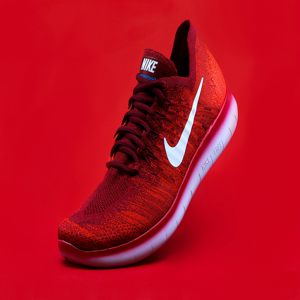

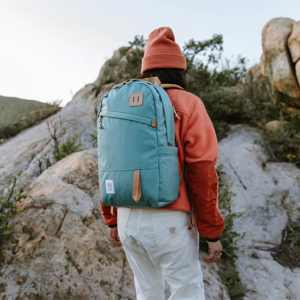

Scenario: Retail Product Descriptions
Goal: Test whether the VLM describes product features consistently.

--- Red Sneaker ---
Prompt 1: Describe this product and its visible features in one sentence.
Model answer: A red Nike shoe with white swoosh and white lettering on the side.

Prompt 2: What product is shown? Mention its color and important details.
Model answer: The shoe is shown.

Prompt 3: Write a short online store description using only details you can see.
Model answer: Nike Free.


--- Backpack ---
Prompt 1: Describe this product and its visible features in one sentence.
Model answer: This image shows a person wearing a red sweater and white pants, with a blue and green backpack on their back. The person is standing in a natural setting, with large rocks and a mountain in the background. The sky is clear, and there are trees and bushes visible in the distance.

Prompt 2: What product is shown? Mention its color and important details.
Model answer: The product is a backpack.

In [ ]:
# YOUR CODE HERE (Try It Yourself)
# Scenario: Retail - Online Product Photo Descriptions

from PIL import Image
from io import BytesIO
import requests

# Load product images directly from URLs
def load_product(url):
    response = requests.get(url)
    response.raise_for_status()
    return Image.open(BytesIO(response.content)).convert("RGB")

# Two product photos
shoe_url = "https://images.unsplash.com/photo-1542291026-7eec264c27ff"

backpack_url = (
    "https://topodesigns.com.au/cdn/shop/files/"
    "i.shgcdn-4_4cade993-9003-4360-be66-8b21b677fd61.jpg"
    "?v=1770701349&width=1024"
)

shoe = load_product(shoe_url)
backpack = load_product(backpack_url)

# Display both test images
display(shoe.resize((300, 300)))
display(backpack.resize((300, 300)))

# Define the workplace scenario
print("Scenario: Retail Product Descriptions")
print("Goal: Test whether the VLM describes product features consistently.")

# Three differently worded prompts for the same task
prompts = [
    "Describe this product and its visible features in one sentence.",
    "What product is shown? Mention its color and important details.",
    "Write a short online store description using only details you can see."
]

# Test both products using the same three prompts
test_images = [
    ("Red Sneaker", shoe),
    ("Backpack", backpack)
]

for image_name, image in test_images:
    print(f"\n--- {image_name} ---")

    for i, prompt in enumerate(prompts, start=1):
        answer = ask(image, prompt)

        print(f"Prompt {i}: {prompt}")
        print(f"Model answer: {answer}")
        print()

### YOUR ANSWER (Audit memo)

*Double click and replace: your five to eight sentence memo to your manager. What you tested, what worked, what failed or wavered, one scenario specific hallucination risk, and your verdict with reasons.*

- I tested SmolVLM-500M-Instruct to see how well it could describe products for an online store. I used two product images, a red sneaker and a backpack, and asked the model three similar questions with different wording for each image. The model correctly recognized the sneaker and described some of its visible features, but its answers became less detailed when I changed the prompts. For the backpack, one response correctly identified the product, while another focused more on the person's sweater instead of the backpack. This showed me that the model did not always focus on the most important object or provide consistent descriptions. One possible hallucination risk is that the model might invent product features that are not actually visible, which could mislead customers. Based on these results, I would recommend using this model only with human review because its descriptions are not reliable enough for automatic publication.

## Section 10: Reflection Questions (Graded, 20 pts, 2 each)

Answer each question in complete sentences directly in its YOUR ANSWER cell. Short bullet answers will not earn full credit. I want your reasoning in your own words.

**Q1. Patches as words.** Explain to a friend with no AI background how a Vision Transformer reads an image, using the patch grid you made in Section 2. Use your own analogy, not one from this notebook.

- A Vision Transformer reads an image by dividing it into smaller patches and looking at how they connect to understand the whole picture. I would compare it to putting together a puzzle, where each piece shows only a small part of the picture, but combining them helps you recognize what it shows. In Section 2, I used 48-pixel and 96-pixel patches on a dog image and noticed that smaller patches divided the image into more pieces. This helps the model work with finer details, while larger patches require less processing but may miss some smaller features.

**Q2. The three part architecture.** A VLM has eyes (vision encoder), a translator (projector), and a voice (language model). When your model hallucinated in Section 7, which part do you suspect was most responsible, and why?

- I think the language model was most responsible for the hallucination in Section 7 because it invented an explanation instead of recognizing that the information was missing. When I asked why sales dropped in July, the model blamed COVID-19, even though the chart only showed sales from January to June. The vision encoder should help recognize what the chart contains, while the projector passes that information to the language model. However, the language model seemed to rely on a possible explanation rather than the actual chart data, which led to an incorrect answer.

**Q3. The prompt is the task.** In Section 4 one model did several jobs. What does this mean for how CV teams will be organized in the workplace: fewer specialist models to maintain, or new problems to manage? Name one of each.

- I think CV teams will need fewer specialist models because one VLM can handle several tasks, such as classification, counting, and describing images. However, they will have more prompts to create, test, and manage because different wording can affect the model's answers. In Section 4, I used the same model for three different tasks just by changing the questions. This could make computer vision systems easier to maintain, but teams would still need to check that each prompt produces accurate and consistent results.

**Q4. Constrained outputs.** Why does "answer with just a number" matter so much when a VLM is wired into software instead of chatting with a person? Give a concrete example of what breaks without it.

- When a VLM connects to software, its answers need to follow a specific format so the program can process them correctly. For example, in Section 4, I asked the model to count the cats and answer with just a number. If the model replied with "There is one cat" instead of "1," a program expecting a number might fail when trying to use that answer in a calculation. This is why constrained outputs matter, especially when other software depends on the model's responses.

**Q5. Small versus frontier.** You used a 500 million parameter open model today; Module 08 covered frontier models thousands of times larger. Name two workplace situations where the small local model is the RIGHT choice even though it is weaker.

- A small local model can be a better choice when a company needs to protect private information because it can process data without sending it to an external service. For example, a hospital could use it to help organize medical documents while keeping patient information on its own systems. Another situation is a retail store that needs to describe hundreds of product images without spending too much money on cloud AI services. Even though a smaller model may be less accurate, it can cost less to operate and give companies more control over their data.

**Q6. Alt text ethics.** Who is harmed when auto generated alt text is wrong, and why is "a human reviews every caption" easier to promise than to deliver at the scale of a real website?

- Incorrect AI-generated alt text can harm people who are blind or have visual impairments because they rely on screen readers to understand images. If the description contains wrong information or leaves out important details, they may misunderstand what the image shows. Having a person review every description sounds like a good solution, but large websites can have thousands of images that change or get updated regularly. This makes it difficult to check everything because human review requires time, money, and enough trained employees to catch mistakes.

**Q7. Ground truth.** In Section 6 you built the chart yourself so you knew the true numbers. Why is this a professional habit, and what goes wrong when teams evaluate AI tools on data where nobody knows the right answers?

- Using ground truth is an important professional habit because it helps teams check whether an AI model gives accurate answers instead of just assuming it works correctly. In Section 6, I knew the correct sales values because we created the chart ourselves, which helped me notice that the model incorrectly said sales increased from April to May. If teams test AI tools on data without knowing the correct answers, they might overlook mistakes and believe the model performs better than it actually does. This could lead companies to use unreliable AI systems and make decisions based on incorrect information.

**Q8. Hallucination versus error.** Using your Section 7 results, explain the difference between a model being wrong and a model hallucinating. Why is the second one harder to catch in a busy workplace?

- A model makes an error when it gives an incorrect answer, such as saying sales increased when they actually decreased. A hallucination happens when the model invents information that the image does not support. In Section 7, the model claimed that COVID-19 caused sales to drop in July, even though the chart did not include July or explain any reasons for sales changes. Hallucinations can be harder to catch in a busy workplace because the explanations may sound convincing, and employees might trust them without checking the original information.

**Q9. The audit mindset.** Your Try It Yourself verdict required taking a position. What evidence would have changed your verdict to the opposite one? Being able to answer this is what separates an audit from an opinion.

- I recommended using the VLM with human review because its product descriptions were not always consistent or accurate. I would have considered unsupervised deployment if the model had correctly identified the main products and described their visible features consistently across all three prompts. Additionally, I would want to test it on more product images to make sure it rarely invents details or focuses on the wrong objects. If those tests showed reliable results with very few errors, I would feel more confident recommending the model without human supervision.

**Q10. Changed mind.** Before this lab, what did you believe about how AI understands images that turned out to be wrong or incomplete? Be specific about which section changed your mind.

- Before this lab, I thought that if an AI model could recognize objects in an image, it could understand most of the information correctly. However, Section 7 changed my mind because the model invented an explanation about COVID-19 causing a sales drop in July, even though the chart did not show July. I realized that recognizing objects and understanding information are not the same thing. This lab taught me that even when an AI model gives confident and detailed answers, I still need to check whether the image actually supports them.

## Section 11: Optional Bonus Challenges (up to +20)

Each completed challenge earns 5 bonus points. Pick any, all, or none. All four are light on compute.

**Bonus A, The tiny sibling (+5):** Load `HuggingFaceTB/SmolVLM-256M-Instruct` (half the size, a fast extra download) and rerun your three Your Turn 1 questions on it. In one or two sentences: what did shrinking the model cost?

**Bonus B, The receipt reader (+5):** Using PIL, draw your own fake receipt image (store name, three items with prices, a total) with `ImageDraw.text`, then ask the model to extract the total and one item price. You know the ground truth because you drew it.

**Bonus C, The patch size probe (+5):** Take one image with small important detail (text or a small object). Show its patch grid at 96 pixels, then ask the model a question about that small detail. Connect what you see in the grid to how the model answered, in one or two sentences.

**Bonus D, Your own photo set (+5):** Complete your Try It Yourself audit entirely with photos you took yourself. If you already did, say so here and point to the cells.

### Bonus A – Comparing Small Vision Language Models

In this experiment, I will compare SmolVLM-500M-Instruct with the smaller SmolVLM-256M-Instruct model. I will ask the smaller model the same three questions about the cat image from Section 3 and compare their responses. My goal is to see whether reducing the model size affects its ability to recognize objects, identify details, and interpret visual information.

In [ ]:
# BONUS A: The Tiny Sibling
# Compare the 500M model with the smaller 256M model.

import gc
import torch
from transformers import AutoProcessor, AutoModelForImageTextToText

# Remove the original model to free GPU memory
del model
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Load the smaller Vision Language Model
SMALL_MODEL_ID = "HuggingFaceTB/SmolVLM-256M-Instruct"

small_processor = AutoProcessor.from_pretrained(SMALL_MODEL_ID)

small_model = AutoModelForImageTextToText.from_pretrained(
    SMALL_MODEL_ID,
    torch_dtype=DTYPE
).to(DEVICE)

print("SmolVLM-256M-Instruct loaded successfully!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  513MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

SmolVLM-256M-Instruct loaded successfully!


In [ ]:

# Create a function for asking the smaller model questions
def ask_small(image, question, max_new_tokens=150):

    # Prepare the image and question for the model
    messages = [{
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": question}
        ]
    }]

    # Convert the conversation into the required format
    prompt = small_processor.apply_chat_template(
        messages,
        add_generation_prompt=True
    )

    inputs = small_processor(
        text=prompt,
        images=[image],
        return_tensors="pt"
    ).to(DEVICE)

    # Generate the response
    with torch.no_grad():
        output = small_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    # Decode only the newly generated answer
    generated_tokens = output[:, inputs["input_ids"].shape[1]:]

    return small_processor.batch_decode(
        generated_tokens,
        skip_special_tokens=True
    )[0].strip()


# Reuse the three questions from Section 3
questions = [
    "What animal is shown in the image?",
    "What color are the cat's eyes?",
    "How does the cat seem to be feeling, and what makes you think that?"
]

# Ask each question and display the answer
for i, question in enumerate(questions, start=1):
    print(f"Question {i}: {question}")
    print("256M Answer:", ask_small(img, question))
    print()


Question 1: What animal is shown in the image?
256M Answer: There is a cat in the image.

Question 2: What color are the cat's eyes?
256M Answer: The cat has green eyes.

Question 3: How does the cat seem to be feeling, and what makes you think that?
256M Answer: The cat appears to be feeling sad or sad.



- The smaller 256M model correctly identified the cat and recognized its green eyes, just like the 500M model. However, the models gave different answers about the cat's mood. The 500M model described the cat as content, while the 256M model said it appeared sad or upset. This showed me that the smaller model could still recognize basic visual details, but its interpretation of more complex information was less consistent. Neither model explained the visual clues behind its answer, so I cannot be sure which interpretation was more accurate.

### Bonus B – Testing Receipt Reading

In this experiment, I will create a sample store receipt using PIL and test whether the VLM can read its numerical information. The receipt will contain three items, their individual prices, and the total. Since I will create the receipt myself, I can compare the model's answers with the correct values and identify any reading errors.

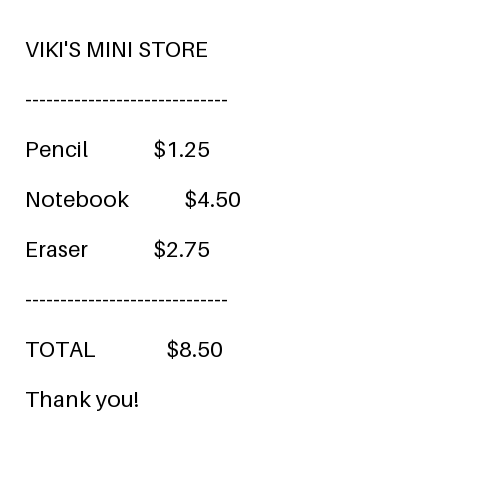

In [ ]:
# BONUS B: Receipt Reader

from PIL import Image, ImageDraw, ImageFont

# Create a blank white receipt
receipt = Image.new("RGB", (500, 500), "white")
draw = ImageDraw.Draw(receipt)

# Use a font available through PIL
font = ImageFont.load_default(size=22)

# Add store information and three purchased items
receipt_lines = [
    "VIKI'S MINI STORE",
    "-----------------------------",
    "Pencil             $1.25",
    "Notebook           $4.50",
    "Eraser             $2.75",
    "-----------------------------",
    "TOTAL              $8.50",
    "Thank you!"
]

# Draw each line on the receipt
for i, line in enumerate(receipt_lines):
    draw.text(
        (25, 35 + i * 50),
        line,
        fill="black",
        font=font
    )

# Display the completed receipt
display(receipt)

In [ ]:
# Ask the VLM to read specific prices from the receipt
receipt_questions = [
    ("What is the total price on the receipt? Answer with just the amount.", "$8.50"),
    ("How much does the pencil cost? Answer with just the amount.", "$1.25")
]

# Compare each model response with the correct value
for question, correct_answer in receipt_questions:

    # Use the smaller model from Bonus A
    answer = ask_small(receipt, question)

    print("Question:", question)
    print("Model answer:", answer)
    print("Correct answer:", correct_answer)
    print()

Question: What is the total price on the receipt? Answer with just the amount.
Model answer: The total price on the receipt is $8.50.
Correct answer: $8.50

Question: How much does the pencil cost? Answer with just the amount.
Model answer: The pencil costs $1.25.
Correct answer: $1.25



- The 256M model correctly read both prices from the receipt I created. It identified the total as \$8.50 and the pencil price as \$1.25, so it answered both questions correctly. However, the model gave complete sentences instead of following my instruction to answer with just the amount. This taught me that the smaller model could recognize numerical information in a clear receipt, but it did not always follow the requested output format.


### Bonus C – Investigating Small Visual Details

In this experiment, I will investigate how larger image patches relate to recognizing small details. I will use the receipt from Bonus B because it contains small text and prices that may be difficult for a model to read. I will display the receipt using 96-pixel patches and test whether the VLM can identify a specific item price.

Receipt with 96-pixel patches:


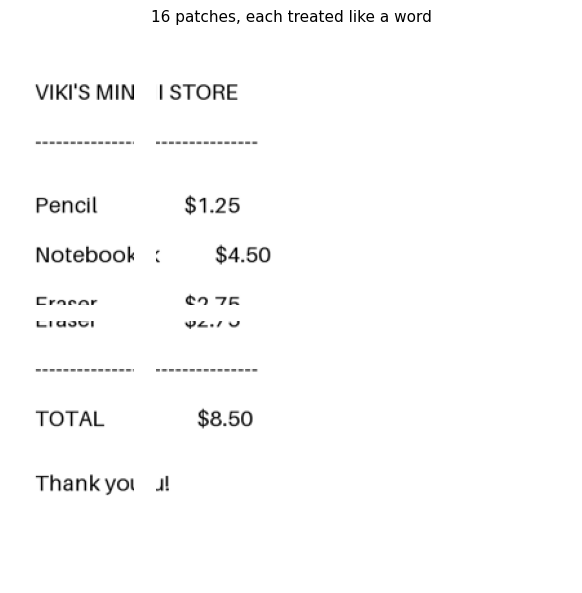


Question: What is the price of the eraser? Answer with just the amount.
Model answer: $2.75.
Correct answer: $2.75


In [ ]:
# BONUS C: Patch-Size Probe

# Resize the receipt so the patch grid divides evenly
receipt_resized = receipt.resize((384, 384))

# Display the receipt with 96-pixel patches
print("Receipt with 96-pixel patches:")
show_patches(receipt_resized, patch_size=96)

# Ask the model to read a small detail
question = "What is the price of the eraser? Answer with just the amount."

answer = ask_small(receipt_resized, question)

print("\nQuestion:", question)
print("Model answer:", answer)
print("Correct answer: $2.75")


- In this experiment, I displayed my receipt using 96-pixel patches, which divided the image into 16 larger pieces. I noticed that some small details, especially the eraser's name and price, became harder to read because the grid lines crossed through the text. However, the model still correctly identified the eraser's price as $2.75. This showed me that the VLM could recognize small text in this example, even when the patch grid made it difficult to see. Since the grid was only a visualization, I cannot conclude that the model processed the image using those exact patches.

##**Conclusion**

Overall, this lab helped me better understand how Vision Transformers and Vision Language Models process images and answer questions about them. I learned how image patches work and how changing prompts allows the same model to perform different tasks, such as classification, counting, and describing objects. The chart-reading and hallucination experiments showed me that even when a model sounds confident, its answers are not always correct. I also learned why human review matters, especially when companies use AI to describe products or provide accessibility information. During the bonus activities, I compared two model sizes, tested receipt reading, and explored how small text appears within larger image patches. I was surprised that the smaller model could correctly read prices from the receipt, even though it struggled with interpreting the cat's mood. Most importantly, this lab taught me that evaluating AI involves more than checking whether the code works. In future projects, I want to focus more on testing model reliability, comparing results with correct answers, and understanding when AI needs human supervision.

## Section 12: Submission Checklist

1. Choose Runtime, then Run all, one final time. Confirm there are no errors and every question and answer pair is visible.
2. Check that every **YOUR ANSWER** cell has your words in it (search the notebook for the word "replace" to find any you missed).
3. File, Download, Download .ipynb, **with all outputs visible**. Do not clear outputs.
4. Name it **L08_LastName_FirstName_ITAI1378.ipynb** and submit the notebook to Canvas. The notebook is the only deliverable.

Today you interviewed images, made one model wear five hats, caught it lying, and wrote a professional audit, all on a model small enough to run on a laptop. In Module 09 the VLM you just tamed becomes the **eyes of an agent** that perceives, reasons, and acts. You already wrote its first perception prompt in Section 8.

*Email or message me if you have any questions.*